In [1]:
import pandas as pd
df = pd.read_csv('diabetes_data_upload.csv')
df

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No,Positive
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No,Positive
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes,Positive
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No,Negative


In [2]:
df = df.replace('No', 0)
df = df.replace('Yes', 1)
df = df.replace('Positive', 1)
df = df.replace('Negative', 0)
df = df.replace('Male', 1)
df = df.replace('Female', 0)
df

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,0,1,1,1,0,1,0,0,1,0,1,1,0,0,0,1
516,48,0,1,1,1,1,1,0,0,1,1,1,1,0,0,0,1
517,58,0,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1
518,32,0,0,0,0,1,0,0,1,1,0,1,0,0,1,0,0


In [3]:
replace = {'Gender':'IsMale'}
df = df.rename(columns = replace)
df.columns.str.lower()

# lowercase everything in columns
df.columns = df.columns.str.lower()
df

,age,ismale,polyuria,polydipsia,sudden weight loss,weakness,polyphagia,genital thrush,visual blurring,itching,irritability,delayed healing,partial paresis,muscle stiffness,alopecia,obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,0,1,1,1,0,1,0,0,1,0,1,1,0,0,0,1
516,48,0,1,1,1,1,1,0,0,1,1,1,1,0,0,0,1
517,58,0,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1
518,32,0,0,0,0,1,0,0,1,1,0,1,0,0,1,0,0


In [4]:
df.to_csv('diabetes_clean_data.csv', index=None)

In [6]:
# import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# import stats libraries
from scipy.stats import chi2_contingency
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.weightstats import ztest

# read csv into a dataframe

df = pd.read_csv('diabetes_clean_data.csv')
df

,age,ismale,polyuria,polydipsia,sudden weight loss,weakness,polyphagia,genital thrush,visual blurring,itching,irritability,delayed healing,partial paresis,muscle stiffness,alopecia,obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,39,0,1,1,1,0,1,0,0,1,0,1,1,0,0,0,1
516,48,0,1,1,1,1,1,0,0,1,1,1,1,0,0,0,1
517,58,0,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1
518,32,0,0,0,0,1,0,0,1,1,0,1,0,0,1,0,0


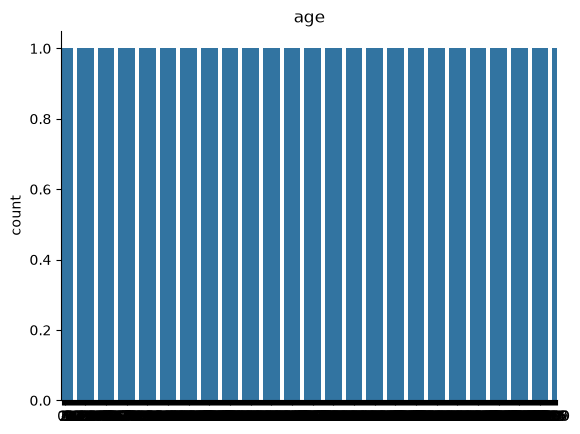

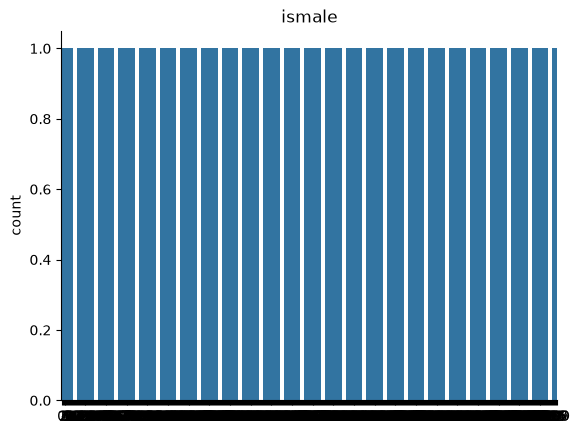

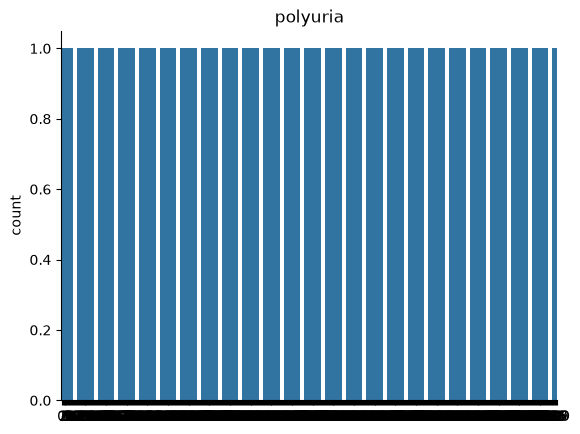

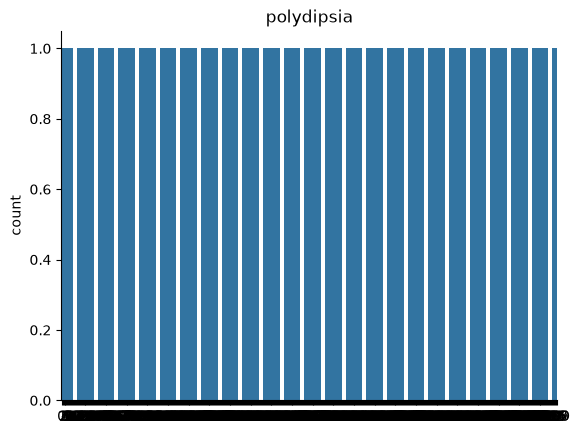

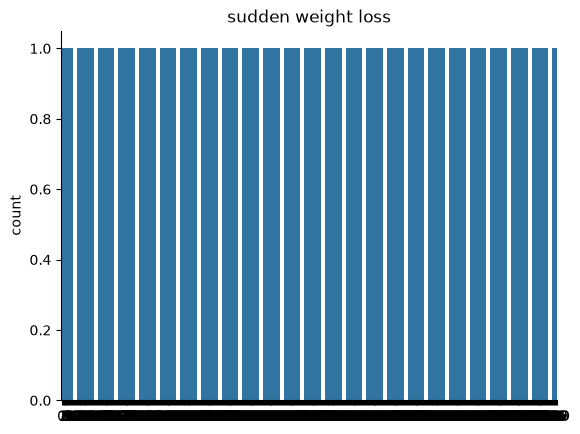

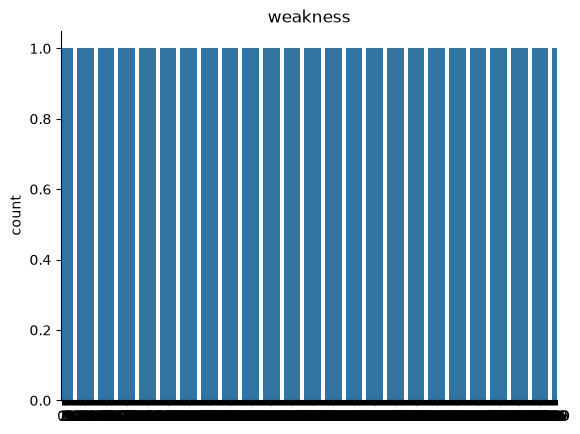

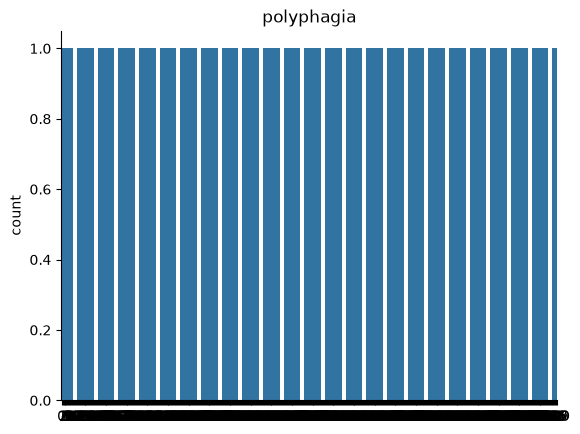

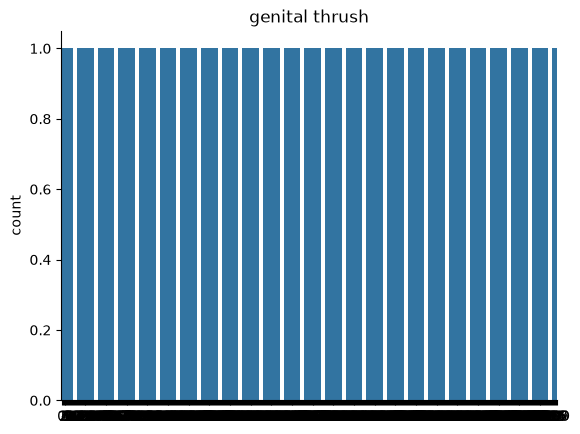

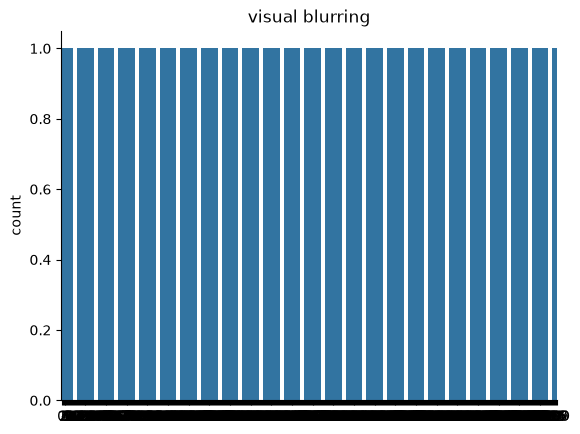

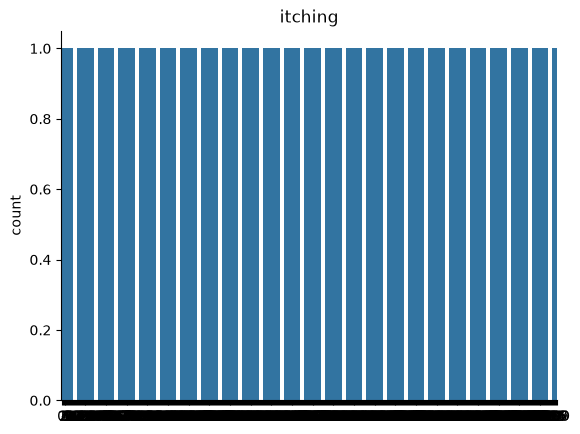

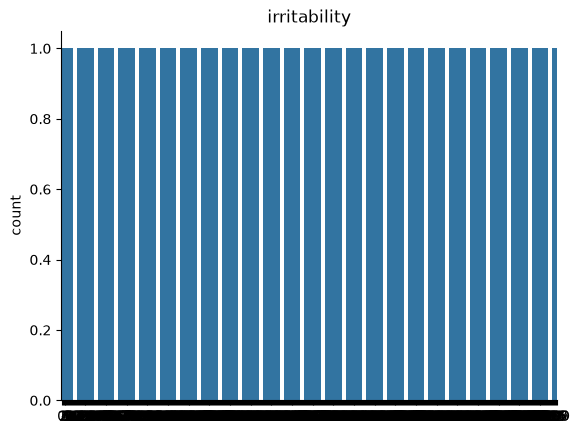

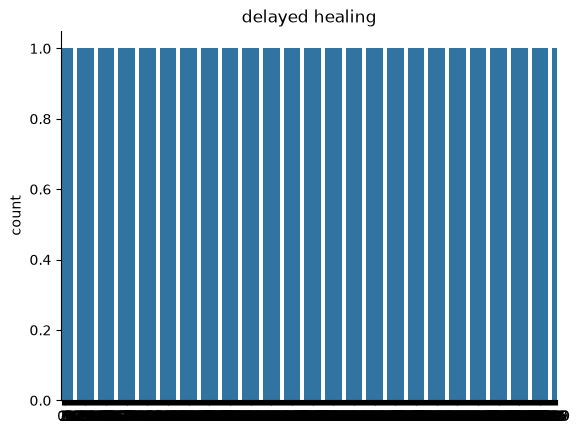

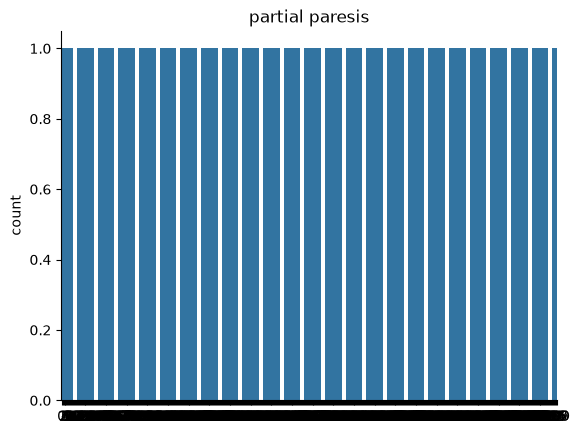

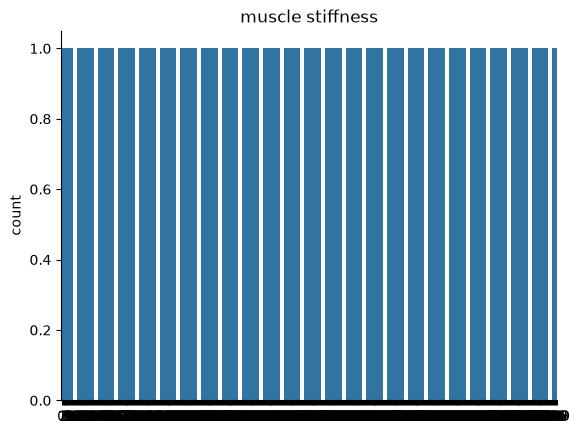

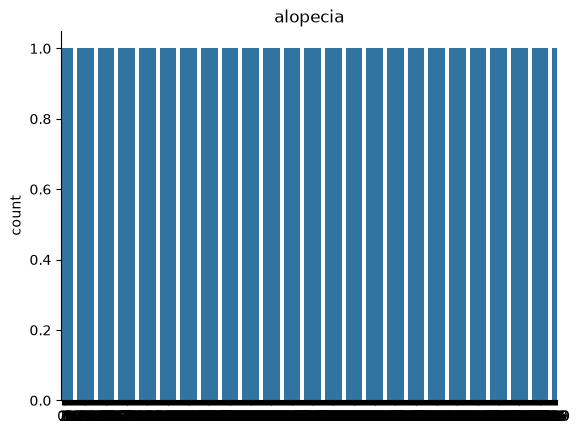

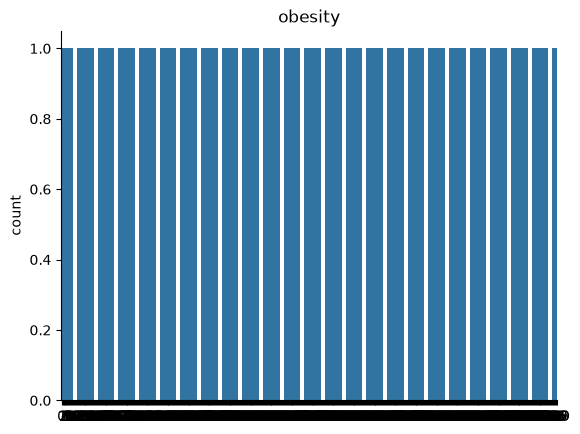

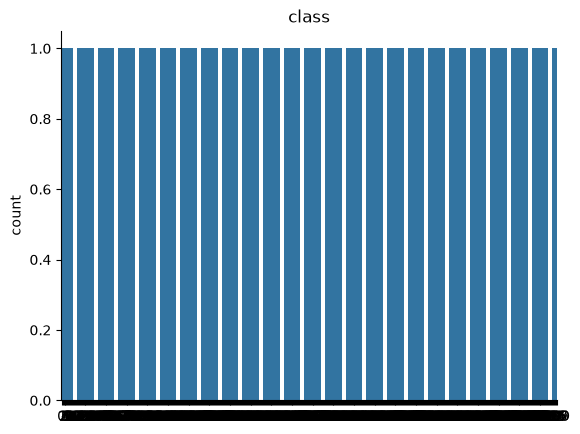

In [8]:
columns = df.columns

# iteratively plot countplot
for column in columns:
    sns.countplot(df[column])
    plt.title(column)
    sns.despine()
    plt.show()

<Axes: xlabel='class', ylabel='age'>

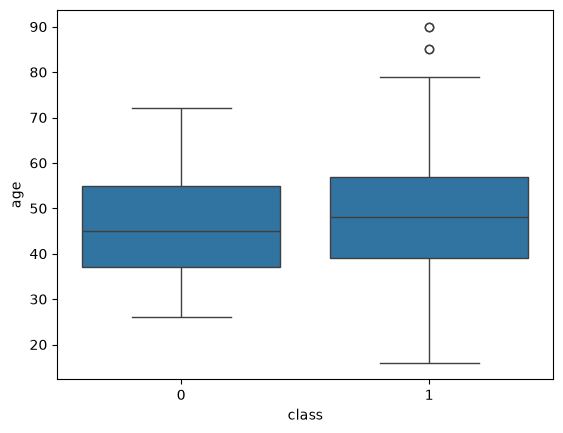

In [10]:
# is there a relationship between age and diabetic status?
sns.boxplot(data=df, x='class', y='age')

no_diabetes = df[df['class'] == 0]
diabetes = df[df['class'] == 1]
ztest(diabetes['age'], no_diabetes['age'])

In [11]:
no_diabetes = df[df['class'] == 0]
diabetes = df[df['class'] == 1]
ztest(diabetes['age'], no_diabetes['age'],)

(np.float64(2.4882300316303065), np.float64(0.012838066562901769))

# get a correlation plot
sns.heatmap(df.corr())

<Axes: >

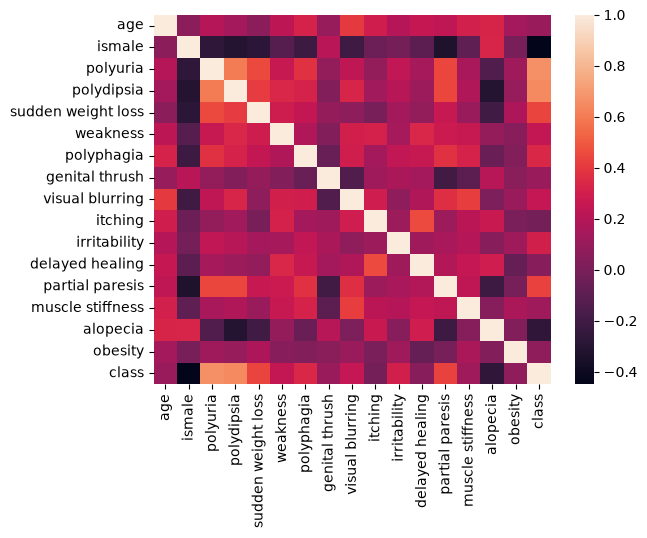

In [15]:
#get a correlation matrix
sns.heatmap(df.corr())

# import machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

In [16]:
# import machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

In [17]:
# prepare our independent and dependent variables

df = pd.read_csv('diabetes_clean_data.csv')

X = df.drop('class', axis=1)
y = df['class']

# split data into train and test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [19]:
dummy = DummyClassifier()
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

# assess DummyClassifier model

confusion_matrix(y_test, dummy_pred)

# use a classification report
print(classification_report(y_test, dummy_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        40
           1       0.62      1.00      0.76        64

    accuracy                           0.62       104
   macro avg       0.31      0.50      0.38       104
weighted avg       0.38      0.62      0.47       104



c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

logr = LogisticRegression(max_iter=10000)
logr.fit(X_train, y_train)
logr_pred = logr.predict(X_test)

confusion_matrix(y_test, logr_pred)

print(classification_report(y_test, logr_pred))

In [20]:
logr = LogisticRegression(max_iter=10000)
logr.fit(X_train, y_train)
logr_pred = logr.predict(X_test)

confusion_matrix(y_test, logr_pred)

print(classification_report(y_test, logr_pred))

              precision    recall  f1-score   support

           0       0.90      0.90      0.90        40
           1       0.94      0.94      0.94        64

    accuracy                           0.92       104
   macro avg       0.92      0.92      0.92       104
weighted avg       0.92      0.92      0.92       104



# try DecisionTree

tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

confusion_matrix(y_test, tree_pred)

print(classification_report(y_test, tree_pred))

In [21]:
# try DecisionTreeClassifier

tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

confusion_matrix(y_test, tree_pred)

print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        40
           1       0.98      0.98      0.98        64

    accuracy                           0.98       104
   macro avg       0.98      0.98      0.98       104
weighted avg       0.98      0.98      0.98       104



# try RandomForest

forest = RandomForestClassifier()
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

confusion_matrix(y_test, forest_pred)

print(classification_report(y_test, forest_pred))

In [22]:
# try RandomForest
forest = RandomForestClassifier()
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

confusion_matrix(y_test, forest_pred)

print(classification_report(y_test, forest_pred))


              precision    recall  f1-score   support

           0       0.95      0.97      0.96        40
           1       0.98      0.97      0.98        64

    accuracy                           0.97       104
   macro avg       0.97      0.97      0.97       104
weighted avg       0.97      0.97      0.97       104



pd.DataFrame({'feature': X.columns, 'importance': forest.feature_importances_}).sort_values('importance', ascending=False)

In [23]:
pd.DataFrame({'feature': X.columns, 'importance': forest.feature_importances_}).sort_values('importance', ascending=False)

,feature,importance
2,polyuria,0.212991
3,polydipsia,0.198591
1,ismale,0.123123
0,age,0.095526
4,sudden weight loss,0.056495
12,partial paresis,0.042661
14,alopecia,0.040377
10,irritability,0.038805
9,itching,0.035098
11,delayed healing,0.027410
